# Storyline 1: When personnel increases, do processing costs also rise?

**Core question: Does the pooled personnel–cost relationship also hold within agencies and in annual growth?**

FY2008–FY2025 | Top ten agencies by requests received

Sequence: levels → annual growth → cost per FTE → findings. This storyline focuses on relationships between resource inputs.

## 1. Sample and measurement

The fixed top ten are ranked by observed cumulative requests received in FY2008–FY2025: DHS, DOJ, DoD, HHS, VA, NARA, SSA, USDA, DOL, and DOS. Agency-overall rows are used without adding components again. Missing years are not filled with zeros; annual changes require consecutive years.

Personnel uses the original type 22 `TotalFullTimeStaffQuantity`. Cost uses the original type 23 `ProcessingCostAmount`. Neither is reconstructed. Observations are retained and flagged when the full-time plus equivalent-FTE sum differs from total FTE by more than 0.02, or processing plus litigation costs differ from total cost by more than USD 1. Blank, nonnumeric, and negative values are missing; zero denominators produce missing ratios.

Costs are expressed in FY2025 prices. Local BLS CPI-U monthly values are averaged over the federal fiscal year (previous October through current September): real cost = nominal cost × CPI_FY2025 / CPI_FYt. Source: [BLS U.S. city average, all-items CPI-U](https://www.bls.gov/regions/northeast/data/consumerpriceindex_us_table.htm), locally collected on November 15, 2026. CPI adjusts purchasing power; it is not a FOIA-specific input-price index.

This notebook runs independently from a fresh Python kernel. All reported relationships are descriptive.


In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({'font.sans-serif': ['DejaVu Sans'], 'axes.unicode_minus': False, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 200)
data_directories = [Path('.'), Path('fa26/storyline'), Path('storyline')]
ROOT = next((p for p in data_directories if (p / 'component_master_no_03_06_11.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Keep the two CSV files beside the notebooks, or run from the repository root.')
SOURCE = ROOT / 'component_master_no_03_06_11.csv'
CPI = ROOT / 'cpi_u_bls_monthly_2007_2025.csv'
raw = pd.read_csv(SOURCE, dtype=str, keep_default_na=False)
fields = {'fte': '22_Personnel__TotalFullTimeStaffQuantity', 'fulltime': '22_Personnel__FullTimeEmployeeQuantity', 'equivalent': '22_Personnel__EquivalentFullTimeEmployeeQuantity', 'cost': '23_Costs__ProcessingCostAmount', 'total': '23_Costs__TotalCostAmount', 'litigation': '23_Costs__LitigationCostAmount', 'received': '01_Requests__ProcessingStatisticsReceivedQuantity', 'processed': '01_Requests__ProcessingStatisticsProcessedQuantity', 'backlog': '26_Backlog__BackloggedRequestQuantity', 'pending': '01_Requests__ProcessingStatisticsPendingAtEndQuantity', 'backlog_current_comparison': '30_ComparisonsRequestsBacklogged__BacklogCurrentYearQuantity', 'backlog_previous_comparison': '30_ComparisonsRequestsBacklogged__BacklogLastYearQuantity'}
labels = {'fte': 'Total FTE', 'fulltime': 'Full-time employees', 'equivalent': 'Equivalent FTE', 'cost': 'Nominal processing cost', 'total': 'Nominal total cost', 'litigation': 'Nominal litigation cost', 'received': 'Requests received', 'processed': 'Requests processed', 'backlog': 'Request backlog', 'pending': 'Pending requests', 'backlog_current_comparison': 'Current-year backlog in same report', 'backlog_previous_comparison': 'Prior-year backlog in same report', 'agency': 'Agency', 'year': 'Fiscal year'}
a = raw[raw['Row Type'].eq('agency_overall') & ~raw['Exclude From Component Sum'].str.strip().str.lower().eq('yes')].copy()
a['agency'] = a['Agency Abbreviation'].str.strip()
a['year'] = pd.to_numeric(a['Fiscal Year'], errors='raise').astype(int)
assert not a.duplicated(['agency', 'year']).any()
for short, col in fields.items():
    v = pd.to_numeric(a[col], errors='coerce')
    a[short] = v.mask(v.lt(0))
a = a.sort_values(['agency', 'year']).reset_index(drop=True)
ranking = a.groupby('agency').received.sum(min_count=1).sort_values(ascending=False)
TOP = ranking.head(10).index.tolist()
names = {'DHS': 'Homeland Security', 'DOJ': 'Justice', 'DoD': 'Defense', 'HHS': 'Health and Human Services', 'VA': 'Veterans Affairs', 'NARA': 'National Archives', 'SSA': 'Social Security Administration', 'USDA': 'Agriculture', 'DOL': 'Labor', 'DOS': 'State'}
colors = {ag: plt.cm.tab10(i) for i, ag in enumerate(TOP)}

def table(frame, mapping=None, digits=3):
    display(frame.rename(columns=mapping or {}).round(digits))

def finish(fig):
    fig.tight_layout()
    plt.show()

def panel_grid():
    return plt.subplots(5, 2, figsize=(15, 19))

def style_year(ax, ag, ylabel):
    ax.set(title=ag, xlabel='Fiscal year', ylabel=ylabel)
    ax.set_xticks([2008, 2012, 2016, 2020, 2025])
display(pd.DataFrame({'Item': ['Main data file', 'SHA-256', 'Local CPI file'], 'Value': [str(SOURCE.resolve()), hashlib.sha256(SOURCE.read_bytes()).hexdigest(), str(CPI)]}))
for short, source in {'simple_days': '14_ProcessingTime__SimpleResponseTime.ResponseTimeMedianDaysValue', 'complex_days': '14_ProcessingTime__ComplexResponseTime.ResponseTimeMedianDaysValue'}.items():
    s = a[source].str.strip()
    a[short] = pd.to_numeric(s, errors='coerce').mask(s.str.fullmatch('<\\s*1'), 1)
    a[short] = a[short].mask(a[short].lt(0))
    a[short + '_lt1'] = s.str.fullmatch('<\\s*1')

def rate_text(values, direction='down'):
    s = values.dropna()
    if not len(s):
        return 'No valid pairs'
    count = int(s.lt(0).sum()) if direction == 'down' else int(s.gt(0).sum())
    return f'{count}/{len(s)}({100 * count / len(s):.1f}%)'

,Item,Value
0,Main data file,C:\Users\11065\Desktop\DS701\MUCROCK\ds-muckro...
1,SHA-256,0674f1a3d96d6c3fc6dc2269b593e132c351bee6e6fedd...
2,Local CPI file,cpi_u_bls_monthly_2007_2025.csv


In [2]:
monthly = pd.read_csv(CPI).melt('year', var_name='month', value_name='cpi')
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly['fy'] = monthly.year + monthly.month.map({m: i >= 9 for i, m in enumerate(months)}).astype(int)
cpi_rows = []
for y in range(2008, 2026):
    g = monthly[monthly.fy.eq(y)]
    assert len(g) == 12 and g.cpi.notna().all()
    cpi_rows.append([y, g.cpi.mean()])
price = pd.DataFrame(cpi_rows, columns=['year', 'cpi'])
a = a.merge(price, on='year', validate='many_to_one')
base = price.loc[price.year.eq(2025), 'cpi'].iloc[0]
for v in ['cost', 'total', 'litigation']:
    a['real_' + v] = a[v] * base / a.cpi
a['fte_gap'] = a.fte - a.fulltime - a.equivalent
a['cost_gap'] = a.total - a.cost - a.litigation
a['fte_flag'] = a.fte_gap.abs().gt(0.02)
a['cost_flag'] = a.cost_gap.abs().gt(1)
a['inventory_flag'] = a.backlog.gt(a.pending)
a['backlog_table_flag'] = (a.backlog - a.backlog_current_comparison).abs().gt(0.01)
a = a.sort_values(['agency', 'year']).reset_index(drop=True)
consecutive = a.year.sub(a.groupby('agency').year.shift()).eq(1)
for v in ['fte', 'real_cost', 'backlog', 'received', 'processed']:
    prev = a.groupby('agency')[v].shift().where(consecutive)
    a['prev_' + v] = prev
    a['g_' + v] = a[v] / prev.where(prev.gt(0)) - 1
    a['delta_' + v] = a[v] - prev
a['revision_gap'] = a.backlog_previous_comparison - a.prev_backlog
d = a[a.agency.isin(TOP)].copy()
flags = ['fte_flag', 'cost_flag', 'inventory_flag', 'backlog_table_flag']
a['previous_type30_current'] = a.groupby('agency').backlog_current_comparison.shift().where(consecutive)
a['type30_cross_gap'] = a.backlog_previous_comparison - a.previous_type30_current
a['cross_flag'] = a.type30_cross_gap.abs().gt(0.01) | a.revision_gap.abs().gt(0.01)
next_con = a.groupby('agency').year.shift(-1).sub(a.year).eq(1)
next_cross = a.groupby('agency').cross_flag.shift(-1).eq(True) & next_con
a['quality_flag'] = a[flags].any(axis=1) | a.cross_flag | next_cross
a['pair_flag'] = a.quality_flag | a.groupby('agency').quality_flag.shift().eq(True)
d = a[a.agency.isin(TOP)].copy()
for metric, numerator, denominator in [('cost_per_fte', 'real_cost', 'fte'), ('backlog_per_fte', 'backlog', 'fte'), ('received_per_fte', 'received', 'fte'), ('processed_per_fte', 'processed', 'fte'), ('cost_per_completed', 'real_cost', 'processed'), ('clearance', 'processed', 'received')]:
    d[metric] = d[numerator] / d[denominator].where(d[denominator].gt(0))
con = d.year.sub(d.groupby('agency').year.shift()).eq(1)
nxt = d.groupby('agency').year.shift(-1).sub(d.year).eq(1)
for v in ['cost_per_fte', 'backlog_per_fte', 'received_per_fte', 'processed_per_fte', 'cost_per_completed', 'simple_days', 'complex_days']:
    prev = d.groupby('agency')[v].shift().where(con)
    d['prev_' + v] = prev
    d['delta_' + v] = d[v] - prev
    d['g_' + v] = d[v] / prev.where(prev.gt(0)) - 1
for v in ['delta_backlog', 'delta_backlog_per_fte', 'delta_processed', 'delta_processed_per_fte']:
    d['next_' + v] = d.groupby('agency')[v].shift(-1).where(nxt)
coverage = d.groupby('agency').agg(First_year=('year', 'min'), Last_year=('year', 'max'), Observed_years=('year', 'size'))
coverage['Cumulative requests received'] = ranking.reindex(coverage.index)
display(coverage.reindex(TOP))
display(Markdown(f'The sample contains {len(d)} agency-year records, accounting for {100 * ranking.loc[TOP].sum() / ranking.sum():.1f}%.'))

,First_year,Last_year,Observed_years,Cumulative requests received
agency,,,,
DHS,2008,2025,18,6986129
DOJ,2008,2025,18,1547577
DoD,2008,2025,18,1121517
HHS,2008,2025,18,862678
VA,2008,2025,18,816975
NARA,2008,2025,18,528895
SSA,2008,2025,18,406106
USDA,2010,2025,16,365205
DOL,2008,2025,18,297922


The sample contains 178 agency-year records, accounting for 85.9%.

In [3]:
table(d.loc[d.fte_flag | d.cost_flag, ['agency', 'year', 'fte_gap', 'cost_gap']], {'agency': 'Agency', 'year': 'Fiscal year', 'fte_gap': 'Total FTE minus component sum', 'cost_gap': 'Total cost minus component sum'}, 2)
display(Markdown('Flagged observations are retained without automatic correction. Cost per FTE measures spending relative to personnel input; it is not average pay.'))

,Agency,Fiscal year,Total FTE minus component sum,Total cost minus component sum
459,DoD,2025,0.91,0.0


Flagged observations are retained without automatic correction. Cost per FTE measures spending relative to personnel input; it is not average pay.

## 2. Personnel and processing costs: are their levels strongly correlated?

Each point is an agency-year. Gray points provide the all-agency background; colors highlight the top ten. Log axes accommodate differences in scale. **Axis transformations and correlation definitions differ:** the table reports original-value Pearson, Spearman rank, and positive-value log Pearson correlations.

Compare all agencies and the pooled top ten, then calculate each agency's time-series correlation. A high all-agency correlation may reflect differences in agency size rather than synchronized annual growth within agencies. Both nominal and real cost correlations are reported.

,Sample,Valid records,Nominal cost Pearson,Real cost Pearson,Real cost Spearman,Valid log records,Log Pearson
0,All agencies,1923,0.930,0.934,0.930,1893,0.893
1,Top ten pooled,178,0.861,0.863,0.878,178,0.901
2,DHS,18,0.823,0.838,0.808,18,0.866
3,DOJ,18,0.724,0.673,0.523,18,0.722
4,DoD,18,0.478,0.032,0.224,18,-0.003
5,HHS,18,-0.017,-0.364,-0.282,18,-0.399
6,VA,18,-0.418,-0.489,-0.100,18,-0.271
7,NARA,18,0.492,0.405,0.357,18,0.227
8,SSA,18,0.775,0.820,0.826,18,0.851
9,USDA,16,-0.139,-0.035,0.065,16,0.053


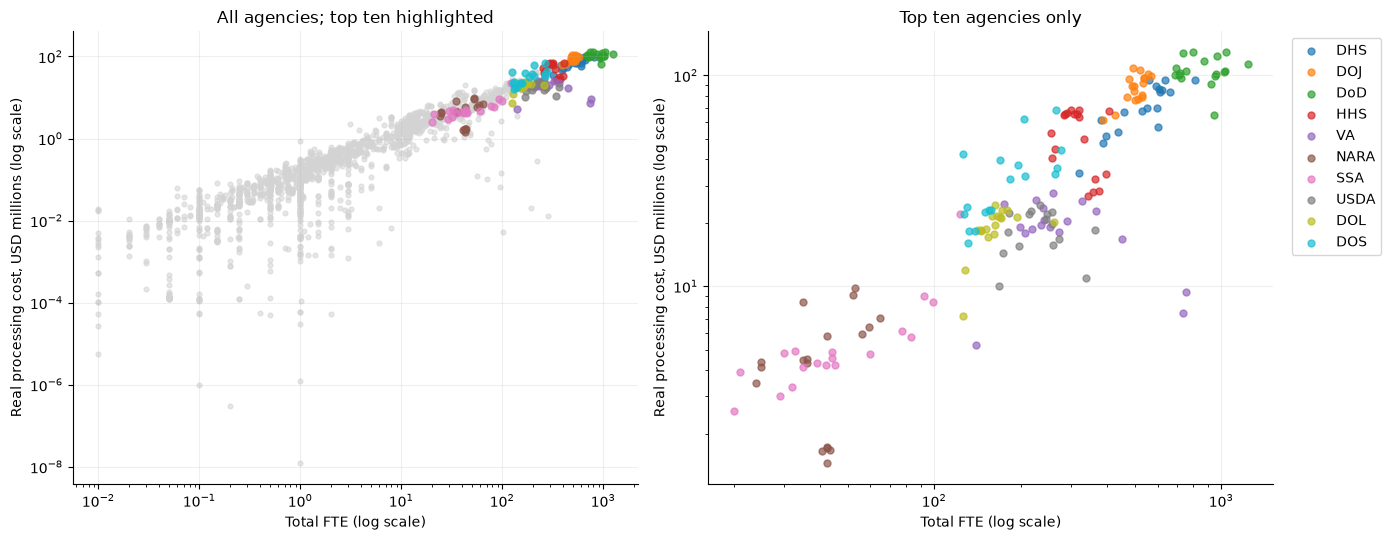

The all-agency correlation between FTE and real cost levels is **0.934**; the pooled top-ten correlation is **0.863**. Agency-specific results are in the table. A pooled correlation does not imply a strong within-agency relationship for every agency.

### 2.1 Interpretation

The pooled top-ten correlation in levels is **0.863**. The highest within-agency coefficient is **DHS(0.838)**, and the lowest is **VA(-0.489)**. The pooled positive correlation cannot replace agency-specific evidence: agency size and common time trends may affect it.

Highest and lowest refer to signed coefficients. Positive values indicate movement in the same direction; negative values indicate opposite movement. Strength also depends on absolute magnitude. The next section examines annual growth.

In [4]:
def correlation(frame, tag):
    q = frame[['fte', 'cost', 'real_cost']].dropna()
    pos = q[q.fte.gt(0) & q.real_cost.gt(0)]
    return [tag, len(q), q.fte.corr(q.cost), q.fte.corr(q.real_cost), q.fte.rank().corr(q.real_cost.rank()), len(pos), np.log(pos.fte).corr(np.log(pos.real_cost))]
corr = pd.DataFrame([correlation(a, 'All agencies'), correlation(d, 'Top ten pooled')] + [correlation(d[d.agency.eq(ag)], ag) for ag in TOP], columns=['Sample', 'Valid records', 'Nominal cost Pearson', 'Real cost Pearson', 'Real cost Spearman', 'Valid log records', 'Log Pearson'])
table(corr)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
bg = a[a.fte.gt(0) & a.real_cost.gt(0)]
axes[0].scatter(bg.fte, bg.real_cost / 1000000.0, color='lightgray', s=12, alpha=0.55, label='All agencies (background)')
for ag in TOP:
    q = d[d.agency.eq(ag) & d.fte.gt(0) & d.real_cost.gt(0)]
    for ax in axes:
        ax.scatter(q.fte, q.real_cost / 1000000.0, label=ag, color=colors[ag], s=25, alpha=0.7)
for ax, title in zip(axes, ['All agencies; top ten highlighted', 'Top ten agencies only']):
    ax.set(xscale='log', yscale='log', xlabel='Total FTE (log scale)', ylabel='Real processing cost, USD millions (log scale)', title=title)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
finish(fig)
display(Markdown(f"The all-agency correlation between FTE and real cost levels is **{corr.iloc[0]['Real cost Pearson']:.3f}**; the pooled top-ten correlation is **{corr.iloc[1]['Real cost Pearson']:.3f}**. Agency-specific results are in the table. A pooled correlation does not imply a strong within-agency relationship for every agency."))
within = corr[corr['Sample'].isin(TOP)].dropna(subset=['Real cost Pearson'])
hi = within.loc[within['Real cost Pearson'].idxmax()]
lo = within.loc[within['Real cost Pearson'].idxmin()]
display(Markdown(f"### 2.1 Interpretation\n\nThe pooled top-ten correlation in levels is **{corr.iloc[1]['Real cost Pearson']:.3f}**. The highest within-agency coefficient is **{hi['Sample']}({hi['Real cost Pearson']:.3f})**, and the lowest is **{lo['Sample']}({lo['Real cost Pearson']:.3f})**. The pooled positive correlation cannot replace agency-specific evidence: agency size and common time trends may affect it.\n\nHighest and lowest refer to signed coefficients. Positive values indicate movement in the same direction; negative values indicate opposite movement. Strength also depends on absolute magnitude. The next section examines annual growth."))

## 3. When staffing increases, do costs grow at the same time?

Each point represents a consecutive-year change. On the left, both growth rates cover t−1 to t. On the right, FTE growth covers t−1 to t and cost growth covers t to t+1. Colors identify agencies.

Above `y=x` in the left panel, cost grows faster than FTE and cost per FTE rises; below it, cost per FTE falls. The right-panel reference line only compares numerical growth rates over different intervals; it cannot indicate same-year unit-cost changes.

Growth rates are not winsorized. Extreme observations can dominate Pearson correlations, so rank correlations are also reported. Missing years and zero baselines do not produce growth rates. Lagged association is not evidence of causality.

,Agency,Same-year pairs,Same-year Pearson,Same-year Spearman,Next-year pairs,Lagged Pearson
0,DHS,17,0.204,0.218,16,-0.002
1,DOJ,17,0.450,0.424,16,-0.111
2,DoD,17,0.278,0.265,16,-0.060
3,HHS,17,0.168,0.407,16,0.216
4,VA,17,0.482,0.108,16,-0.355
5,NARA,17,0.002,0.298,16,0.175
6,SSA,17,0.519,0.730,16,0.213
7,USDA,15,-0.121,0.032,14,-0.166
8,DOL,17,0.287,0.343,16,-0.037
9,DOS,17,0.549,0.507,16,-0.529


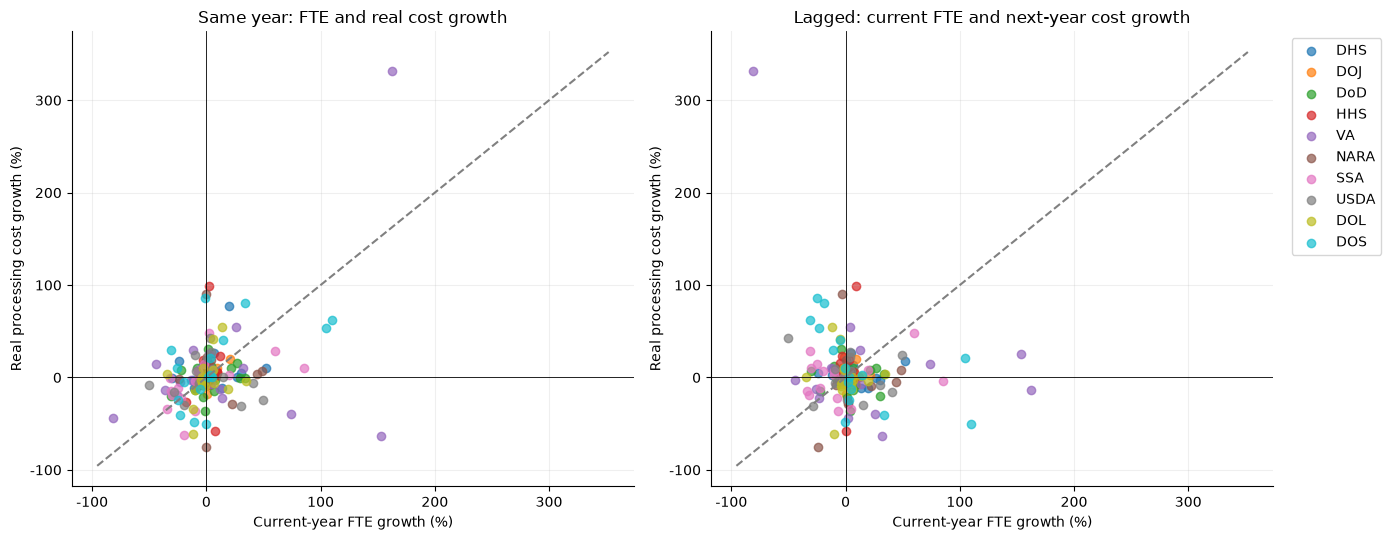

### 3.1 Interpretation

The highest same-year growth correlation is **DOS(0.549)**, and the lowest is **USDA(-0.121)**. Among **88** comparable staffing-increase records, **62** also have an increase in real cost. Lagged correlations range from **-0.529—0.216**.

Annual personnel and spending growth move together to different degrees across agencies. Strong correlation in levels does not imply proportionate cost increases after every staffing increase. Cost growing more slowly than FTE implies falling cost per FTE; faster cost growth implies rising cost per FTE.

### 3.2 All-agency context

Across all agencies in FY2008–FY2025, **121 agencies** have at least one staffing-increase year with comparable real cost growth; **116 agencies** have at least one year when both increase. Out of **648** comparable staffing-increase agency-years, **462** also show increased real processing cost, or **71.3%**.

A joint increase means both FTE and real processing cost grow over the same consecutive-year interval; their growth rates need not match. This is all-agency context; detailed top-ten results remain above. The agency-year percentage is not a percentage of agencies and does not establish that staffing caused cost growth.

In [5]:
a['next_g_cost'] = a.groupby('agency').g_real_cost.shift(-1).where(a.groupby('agency').year.shift(-1).sub(a.year).eq(1))
d = a[a.agency.isin(TOP)].copy()
growth_rows = []
for ag in TOP:
    q = d[d.agency.eq(ag)]
    same = q[['g_fte', 'g_real_cost']].dropna()
    lag = q[['g_fte', 'next_g_cost']].dropna()
    growth_rows.append([ag, len(same), same.g_fte.corr(same.g_real_cost), same.g_fte.rank().corr(same.g_real_cost.rank()), len(lag), lag.g_fte.corr(lag.next_g_cost)])
growth = pd.DataFrame(growth_rows, columns=['Agency', 'Same-year pairs', 'Same-year Pearson', 'Same-year Spearman', 'Next-year pairs', 'Lagged Pearson'])
table(growth)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ag in TOP:
    q = d[d.agency.eq(ag)]
    axes[0].scatter(q.g_fte * 100, q.g_real_cost * 100, label=ag, color=colors[ag], alpha=0.7)
    axes[1].scatter(q.g_fte * 100, q.next_g_cost * 100, label=ag, color=colors[ag], alpha=0.7)
for ax, title in zip(axes, ['Same year: FTE and real cost growth', 'Lagged: current FTE and next-year cost growth']):
    lo = min(ax.get_xlim()[0], ax.get_ylim()[0])
    hi = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([lo, hi], [lo, hi], ls='--', color='gray')
    ax.axhline(0, color='black', lw=0.6)
    ax.axvline(0, color='black', lw=0.6)
    ax.set(title=title, xlabel='Current-year FTE growth (%)', ylabel='Real processing cost growth (%)')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
finish(fig)
hi = growth.loc[growth['Same-year Pearson'].idxmax()]
lo = growth.loc[growth['Same-year Pearson'].idxmin()]
joint = d[d.g_fte.gt(0) & d.g_real_cost.notna()]
display(Markdown(f"### 3.1 Interpretation\n\nThe highest same-year growth correlation is **{hi['Agency']}({hi['Same-year Pearson']:.3f})**, and the lowest is **{lo['Agency']}({lo['Same-year Pearson']:.3f})**. Among **{len(joint)}** comparable staffing-increase records, **{int(joint.g_real_cost.gt(0).sum())}** also have an increase in real cost. Lagged correlations range from **{growth['Lagged Pearson'].min():.3f}—{growth['Lagged Pearson'].max():.3f}**.\n\nAnnual personnel and spending growth move together to different degrees across agencies. Strong correlation in levels does not imply proportionate cost increases after every staffing increase. Cost growing more slowly than FTE implies falling cost per FTE; faster cost growth implies rising cost per FTE."))
all_growth_pairs = a.dropna(subset=['g_fte', 'g_real_cost']).copy()
all_staff_up = all_growth_pairs[all_growth_pairs.g_fte.gt(0)]
all_both_up = all_staff_up[all_staff_up.g_real_cost.gt(0)]
overall_share = 100 * len(all_both_up) / len(all_staff_up) if len(all_staff_up) else np.nan
display(Markdown(f'### 3.2 All-agency context\n\nAcross all agencies in FY2008–FY2025, **{all_staff_up.agency.nunique()} agencies** have at least one staffing-increase year with comparable real cost growth; **{all_both_up.agency.nunique()} agencies** have at least one year when both increase. Out of **{len(all_staff_up)}** comparable staffing-increase agency-years, **{len(all_both_up)}** also show increased real processing cost, or **{overall_share:.1f}%**.\n\nA joint increase means both FTE and real processing cost grow over the same consecutive-year interval; their growth rates need not match. This is all-agency context; detailed top-ten results remain above. The agency-year percentage is not a percentage of agencies and does not establish that staffing caused cost growth.'))

## 4. How much processing cost corresponds to each FTE?

Real processing cost / total FTE measures the ratio of resource inputs, not average pay. First index FTE, nominal cost, and real cost, then display actual cost per FTE. Each agency's first valid year equals 100; agencies with different base years cannot be compared by index levels.

Cost-per-FTE growth is exactly `(1 + cost growth) / (1 + FTE growth) - 1`, not the difference between the two growth percentages.

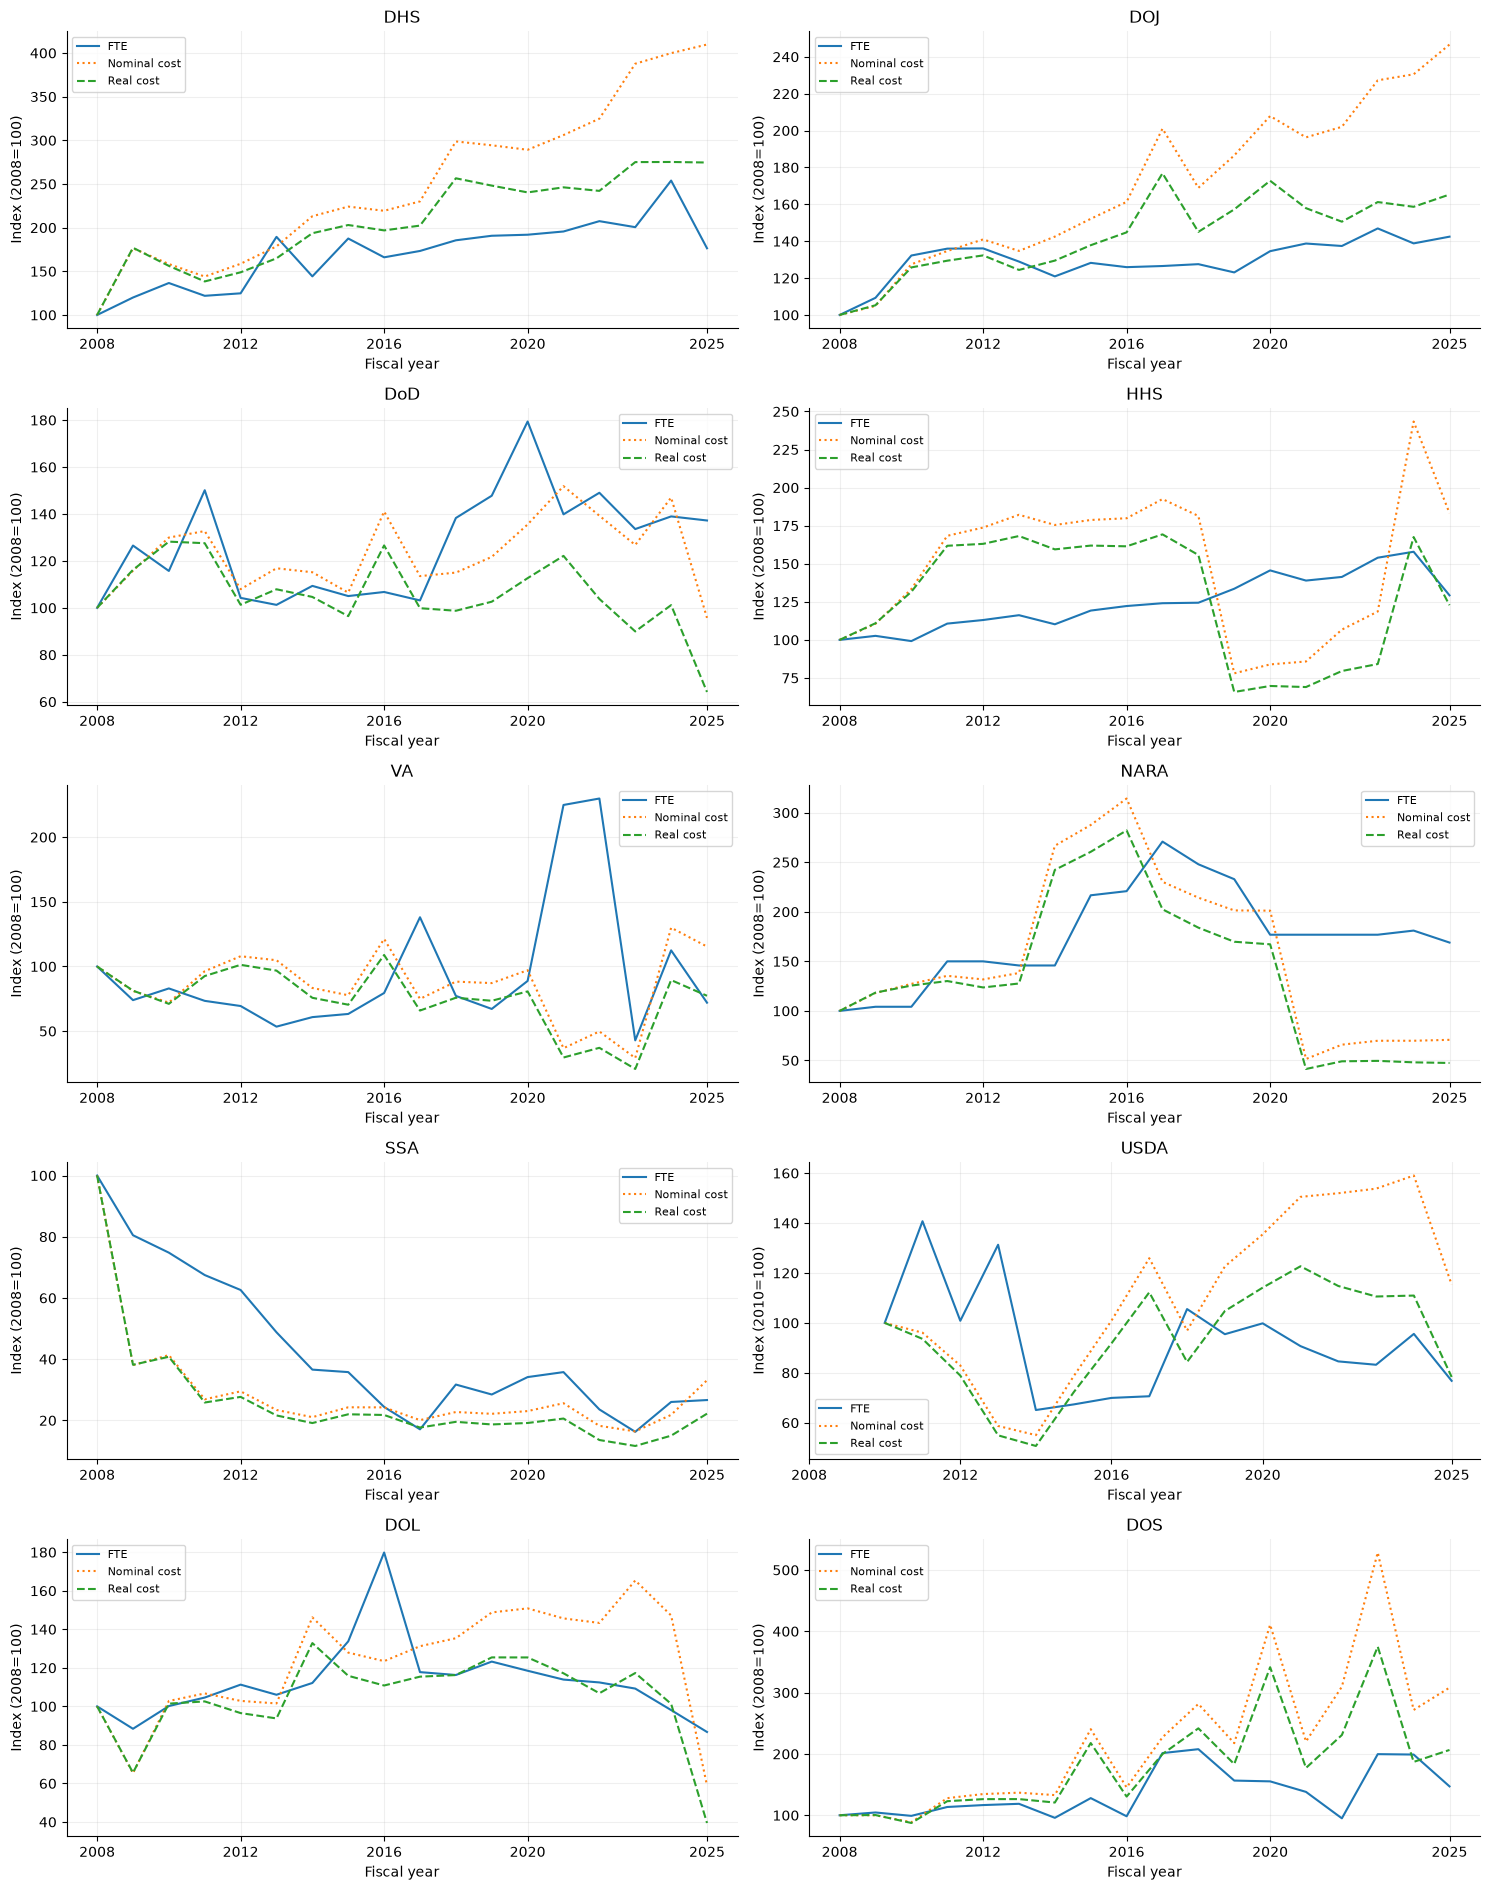

,Agency,First FY,Last FY,Initial FTE,Final FTE,FTE change (%),Real cost change (%),Cost per FTE change (%)
0,DHS,2008,2025,318.61,562.00,76.39,174.60,55.68
1,DOJ,2008,2025,388.81,553.90,42.46,65.31,16.04
2,DoD,2008,2025,689.65,946.38,37.23,-35.83,-53.24
3,HHS,2008,2025,257.32,332.60,29.26,22.78,-5.01
4,VA,2008,2025,326.70,235.19,-28.01,-22.67,7.42
5,NARA,2008,2025,24.00,40.55,68.96,-52.54,-71.91
6,SSA,2008,2025,123.00,32.77,-73.36,-77.81,-16.70
7,USDA,2010,2025,257.83,197.98,-23.21,-21.66,2.02
8,DOL,2008,2025,145.29,125.98,-13.29,-60.52,-54.46
9,DOS,2008,2025,132.65,195.13,47.10,106.50,40.38


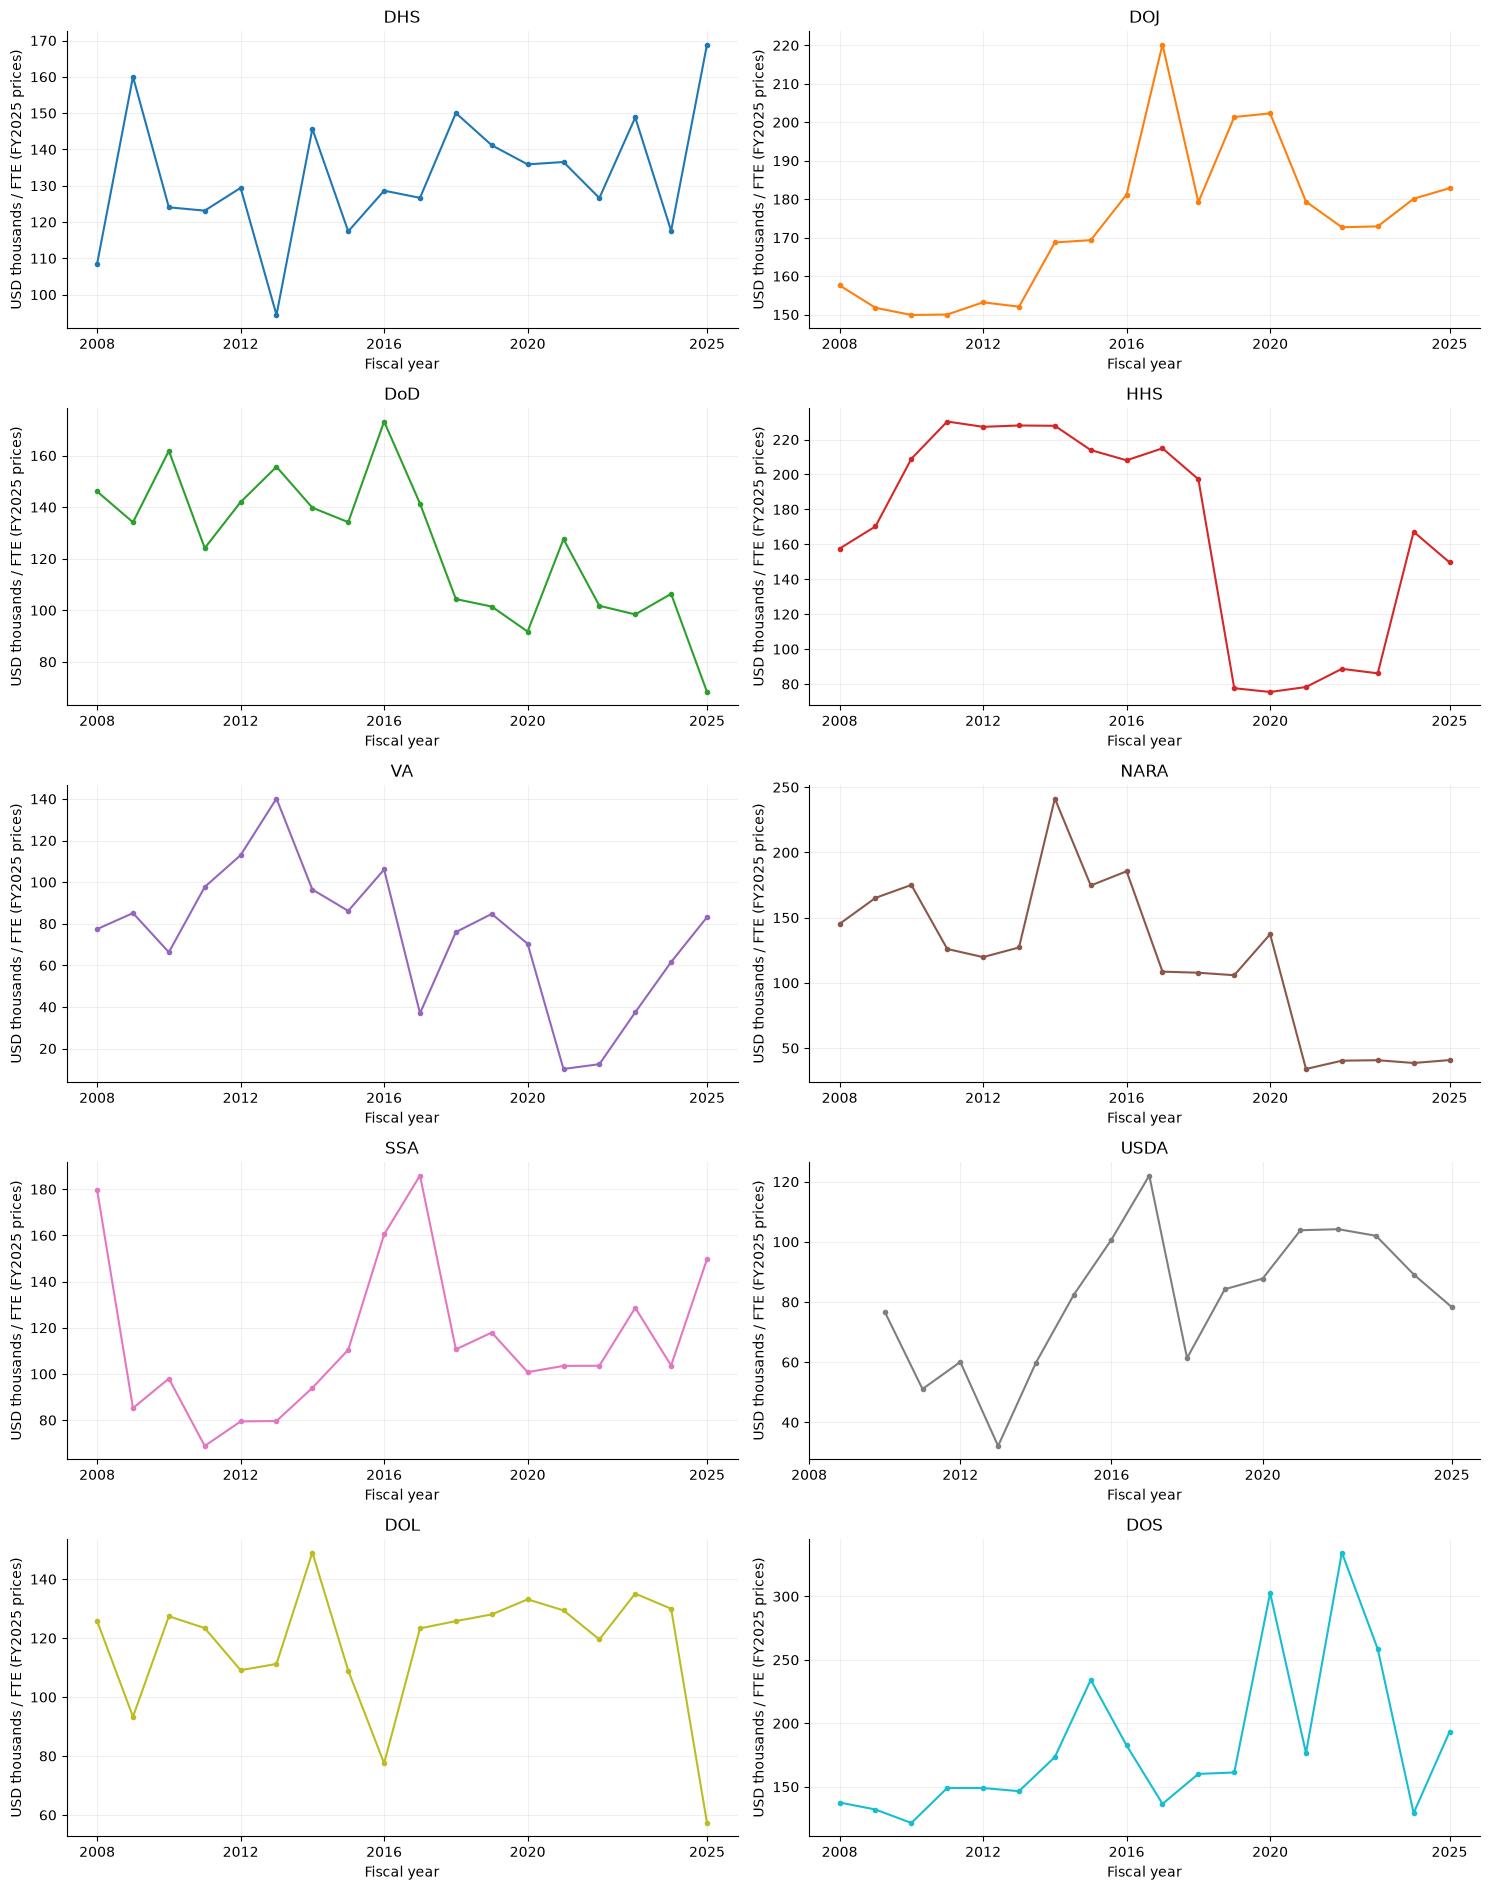

,Valid years,Median (USD thousands/FTE),Minimum,Maximum
agency,,,,
DHS,18,129.03,94.40,168.89
DOJ,18,172.82,149.91,220.21
DOL,18,124.58,57.29,149.03
DOS,18,160.73,121.52,334.54
DoD,18,130.86,68.31,173.21
HHS,18,183.78,75.45,230.34
NARA,18,122.87,33.99,241.32
SSA,18,103.60,68.81,185.92
USDA,16,83.30,32.14,122.05


### 4.1 Interpretation

In FY2025, the lowest real processing cost per FTE is **NARA(40.8 thousand USD)**; the highest is **DOS(193.2 thousand USD)**. Comparing each agency's own endpoints, **5** agencies show increases and **5** show decreases.

This section describes spending per unit of personnel input; output and task difficulty cannot be determined from it alone. Checking whether low cost accompanies low output requires types 01 (processed requests), 22 (personnel), and 23 (processing cost). Checking whether higher cost accompanies more complex work requires types 16/17/18 (simple, complex, expedited completions) and type 14 (track-specific processing time). Complex share is only a task-mix proxy and cannot establish why costs are high. These checks appear in Storyline 3 and are not treated here as verified explanations. Input-data flags for the latest-year extremes are: lowest False, highest False.

In [6]:
d['cost_per_fte'] = d.real_cost / d.fte.where(d.fte.gt(0))
fig, axes = panel_grid()
endpoints = []
for ax, ag in zip(axes.flat, TOP):
    q = d[d.agency.eq(ag)].sort_values('year').dropna(subset=['fte', 'real_cost', 'cost'])
    f, l = (q.iloc[0], q.iloc[-1])
    for v, label, ls in [('fte', 'FTE', '-'), ('cost', 'Nominal cost', ':'), ('real_cost', 'Real cost', '--')]:
        if f[v] > 0:
            ax.plot(q.year, 100 * q[v] / f[v], label=label, ls=ls)
    style_year(ax, ag, f'Index ({int(f.year)}=100)')
    ax.legend(fontsize=8)
    endpoints.append([ag, int(f.year), int(l.year), f.fte, l.fte, 100 * (l.fte / f.fte - 1), 100 * (l.real_cost / f.real_cost - 1), 100 * (l.cost_per_fte / f.cost_per_fte - 1)])
finish(fig)
endpoint = pd.DataFrame(endpoints, columns=['Agency', 'First FY', 'Last FY', 'Initial FTE', 'Final FTE', 'FTE change (%)', 'Real cost change (%)', 'Cost per FTE change (%)'])
table(endpoint, digits=2)
fig, axes = panel_grid()
for ax, ag in zip(axes.flat, TOP):
    q = d[d.agency.eq(ag)]
    ax.plot(q.year, q.cost_per_fte / 1000, color=colors[ag], marker='o', ms=3)
    style_year(ax, ag, 'USD thousands / FTE (FY2025 prices)')
finish(fig)
unit = d.groupby('agency').cost_per_fte.agg(['count', 'median', 'min', 'max'])
unit[['median', 'min', 'max']] /= 1000
table(unit, {'count': 'Valid years', 'median': 'Median (USD thousands/FTE)', 'min': 'Minimum', 'max': 'Maximum'}, 2)
latest_cost = d[d.year.eq(d.year.max())].dropna(subset=['cost_per_fte']).sort_values('cost_per_fte')
low, high = (latest_cost.iloc[0], latest_cost.iloc[-1])
display(Markdown(f"### 4.1 Interpretation\n\nIn FY{int(d.year.max())}, the lowest real processing cost per FTE is **{low.agency}({low.cost_per_fte / 1000:.1f} thousand USD)**; the highest is **{high.agency}({high.cost_per_fte / 1000:.1f} thousand USD)**. Comparing each agency's own endpoints, **{int(endpoint['Cost per FTE change (%)'].gt(0).sum())}** agencies show increases and **{int(endpoint['Cost per FTE change (%)'].lt(0).sum())}** show decreases.\n\nThis section describes spending per unit of personnel input; output and task difficulty cannot be determined from it alone. Checking whether low cost accompanies low output requires types 01 (processed requests), 22 (personnel), and 23 (processing cost). Checking whether higher cost accompanies more complex work requires types 16/17/18 (simple, complex, expedited completions) and type 14 (track-specific processing time). Complex share is only a task-mix proxy and cannot establish why costs are high. These checks appear in Storyline 3 and are not treated here as verified explanations. Input-data flags for the latest-year extremes are: lowest {bool(low.fte_flag or low.cost_flag)}, highest {bool(high.fte_flag or high.cost_flag)}."))

## 5. Answering the core question

In [7]:
display(Markdown(f"The pooled top-ten correlation between personnel and real cost levels is **{corr.iloc[1]['Real cost Pearson']:.3f}**, while agency-specific same-year growth correlations range from **{growth['Same-year Pearson'].min():.3f} to {growth['Same-year Pearson'].max():.3f}**.\n\nScale relationships differ from annual growth relationships. A high pooled correlation does not mean every agency increases costs proportionately when staffing rises. Real cost per FTE increases between each agency's endpoints in **{int(endpoint['Cost per FTE change (%)'].gt(0).sum())}** agencies.\n\nPersonnel and cost reporting scope, price adjustment, and agency-specific trends may affect these associations. This analysis estimates neither the causal cost of adding one employee nor processing efficiency."))

The pooled top-ten correlation between personnel and real cost levels is **0.863**, while agency-specific same-year growth correlations range from **-0.121 to 0.549**.

Scale relationships differ from annual growth relationships. A high pooled correlation does not mean every agency increases costs proportionately when staffing rises. Real cost per FTE increases between each agency's endpoints in **5** agencies.

Personnel and cost reporting scope, price adjustment, and agency-specific trends may affect these associations. This analysis estimates neither the causal cost of adding one employee nor processing efficiency.

## Appendix: annual personnel and real cost changes

In [8]:
annual = d[['agency', 'year', 'fte', 'real_cost', 'g_fte', 'g_real_cost']].copy()
annual['real_cost'] /= 1000000.0
annual[['g_fte', 'g_real_cost']] *= 100
table(annual, {**labels, 'real_cost': 'Real processing cost (USD millions)', 'g_fte': 'Personnel growth (%)', 'g_real_cost': 'Real cost growth (%)'}, 2)

,Agency,Fiscal year,Total FTE,Real processing cost (USD millions),Personnel growth (%),Real cost growth (%)
280,DHS,2008,318.61,34.57,NaN,NaN
281,DHS,2009,382.31,61.18,19.99,77.00
282,DHS,2010,435.25,54.00,13.85,-11.75
283,DHS,2011,388.54,47.84,-10.73,-11.39
284,DHS,2012,397.61,51.46,2.33,7.55
285,DHS,2013,603.66,56.99,51.82,10.75
286,DHS,2014,459.48,66.93,-23.88,17.45
287,DHS,2015,597.57,70.18,30.05,4.85
288,DHS,2016,528.98,68.05,-11.48,-3.03
289,DHS,2017,552.19,69.94,4.39,2.79


## Sources and reproduction

FOIA data: `component_master_no_03_06_11.csv` in this directory, from branch fa26-Tianqi, commit `c99a9a4af91d558da9a83c3c8e987f79de710f0a`. Price adjustment uses `cpi_u_bls_monthly_2007_2025.csv`. Keep both CSVs beside this notebook, select a Python kernel, and Run All. Dependencies: pandas, NumPy, Matplotlib, and IPython. Execution requires no network access, does not modify source data, and does not read variables or outputs from another notebook.

Independent storylines: [Personnel and costs](FOIA-story-1-personnel-costs.ipynb) · [Staffing and backlog](FOIA-story-2-staffing-backlog.ipynb) · [Cost, output, and task mix](FOIA-story-3-cost-output-complexity.ipynb). The original complete analysis is retained as a working reference.
